In [14]:
#CIND 820: Capstone Project:Saphora Product Review


In [74]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report, make_scorer
)

pd.set_option("display.max_colwidth", 160)
# Load dataset safely
saphora = pd.read_csv(
    r"C:\Users\akaze\OneDrive\Documents\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\Sephora Products and Skincare Reviews_uncleaned.csv",
    low_memory=False
)
saphora.dtypes


Unnamed: 0                    int64
author_id                    object
rating                        int64
is_recommended              float64
helpfulness                 float64
total_feedback_count          int64
total_neg_feedback_count      int64
total_pos_feedback_count      int64
submission_time              object
review_text                  object
review_title                 object
skin_tone                    object
eye_color                    object
skin_type                    object
hair_color                   object
product_id                   object
product_name                 object
brand_name                   object
price_usd                   float64
dtype: object

In [127]:
saphora.head()

,unnamed:_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,...,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd,review_len,sentiment_bin,rating_3cls
0,0.00000,1945004256,1.0,1.0,0.000000,0.001637,0.001726,0.000000,2022-12-10,"I absolutely L-O-V-E this oil. I have acne prone skin in my 30’s, and use this on top of my evening cream as a final moisture lock-in. Its smell is a spa-gr...",...,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,0.032683,932,1.0,mid
1,0.00002,5478482359,0.5,1.0,0.333333,0.002455,0.001726,0.001289,2021-12-17,I gave this 3 stars because it give me tiny little white heads from first use ima give it few more days before making a final decision on keeping or returni...,...,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,0.032683,291,0.0,low
2,0.00004,29002209922,1.0,1.0,1.000000,0.001637,0.000000,0.002577,2021-06-07,Works well as soon as I wash my face and pat dry it. Smells amazing too.,...,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,0.032683,72,1.0,mid
3,0.00006,7391078463,1.0,1.0,1.000000,0.001637,0.000000,0.002577,2021-05-21,"this oil helped with hydration and breakouts, I love this!!",...,brown,combination,blonde,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,0.032683,59,1.0,mid
4,0.00008,1766313888,1.0,1.0,1.000000,0.010638,0.000000,0.016753,2021-03-29,"This is my first product review ever so that should tell you how much I love this. I actually bought this in my low 20s but I was drinking, eating terrible ...",...,brown,combination,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,0.032683,956,1.0,mid


In [50]:

null_counts = saphora.isnull().sum()
null_pct = (saphora.isnull().mean() * 100).round(2)
null_summary = pd.concat([null_counts.rename('null_count'), null_pct.rename('null_%')], axis=1)
display(null_summary.sort_values('null_count', ascending=False).head(20))

# Save summary
null_summary.to_csv('sephora_uncleaned_null_summary.csv')
print('✅ Null summary saved as sephora_uncleaned_null_summary.csv')

,null_count,null_%
review_title,14378,28.77
helpfulness,13455,26.92
hair_color,8851,17.71
skin_tone,7201,14.41
eye_color,6260,12.53
is_recommended,3817,7.64
skin_type,3631,7.27
review_text,59,0.12
brand_name,0,0.00
product_name,0,0.00


✅ Null summary saved as sephora_uncleaned_null_summary.csv


In [54]:

# -----------------------------
# 1️⃣ Load and normalize schema
# -----------------------------

RAW_PATH = r"C:\Users\akaze\OneDrive\Documents\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\Sephora Products and Skincare Reviews_uncleaned.csv"

# Read CSV safely
saphora = pd.read_csv(RAW_PATH, low_memory=False)

# Normalize column names: lowercase, remove spaces
saphora.columns = [c.strip().lower().replace(" ", "_") for c in saphora.columns]

# Helper to pick first available column
def first_existing(_df, candidates):
    for c in candidates:
        if c in _df.columns:
            return c
    return None

# Identify key columns dynamically
col_rating    = first_existing(saphora, ["rating", "stars", "star_rating"])
col_review    = first_existing(saphora, ["review_text", "review", "text", "content"])
col_title     = first_existing(saphora, ["review_title", "title", "summary"])
col_price     = first_existing(saphora, ["price"])
col_brand     = first_existing(saphora, ["brand"])
col_product   = first_existing(saphora, ["product_name", "product", "item_name"])
col_skin_type = first_existing(saphora, ["skin_type"])
col_skin_tone = first_existing(saphora, ["skin_tone"])
col_helpful   = first_existing(saphora, ["helpfulness", "helpful_votes", "feedback"])

print("✅ Columns mapped:")
print(" rating   ->", col_rating)
print(" review   ->", col_review)
print(" title    ->", col_title)
print(" price    ->", col_price)
print(" brand    ->", col_brand)
print(" product  ->", col_product)
print(" skin_type->", col_skin_type)
print(" skin_tone->", col_skin_tone)
print(" helpful  ->", col_helpful)
print("Rows x Cols:", saphora.shape)
saphora.head(3)


✅ Columns mapped:
 rating   -> rating
 review   -> review_text
 title    -> review_title
 price    -> None
 brand    -> None
 product  -> product_name
 skin_type-> skin_type
 skin_tone-> skin_tone
 helpful  -> helpfulness
Rows x Cols: (49977, 19)


,unnamed:_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1945004256,5,1.0,0.000000,2,2,0,2022-12-10,"I absolutely L-O-V-E this oil. I have acne prone skin in my 30’s, and use this on top of my evening cream as a final moisture lock-in. Its smell is a spa-gr...",A must have!,lightMedium,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0
1,1,5478482359,3,1.0,0.333333,3,2,1,2021-12-17,I gave this 3 stars because it give me tiny little white heads from first use ima give it few more days before making a final decision on keeping or returni...,it keeps oily skin under control,mediumTan,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0
2,2,29002209922,5,1.0,1.000000,2,0,2,2021-06-07,Works well as soon as I wash my face and pat dry it. Smells amazing too.,Worth the money!,lightMedium,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0


In [56]:
# ==========================================================
# 3️⃣ Data Cleaning for Sephora Dataset
# ==========================================================

# --- Convert rating to numeric and filter valid range (1–5)
if col_rating:
    saphora[col_rating] = pd.to_numeric(saphora[col_rating], errors="coerce")
    saphora = saphora[(saphora[col_rating] >= 1) & (saphora[col_rating] <= 5)]

# --- Convert price to numeric (if it exists)
if col_price:
    saphora[col_price] = pd.to_numeric(saphora[col_price], errors="coerce")

# --- Clean text columns: strip whitespace and cast to string
for c in [col_review, col_title, col_brand, col_product, col_skin_type, col_skin_tone]:
    if c and c in saphora.columns:
        saphora[c] = saphora[c].astype(str).str.strip()

# --- Remove duplicate rows using key columns
dup_keys = [c for c in [col_product, col_brand, col_title, col_review, col_rating] if c and c in saphora.columns]
if dup_keys:
    before = len(saphora)
    saphora = saphora.drop_duplicates(subset=dup_keys)
    after = len(saphora)
    print(f"✅ Removed duplicates: {before - after}")

print("✅ After cleaning:", saphora.shape)

✅ Removed duplicates: 121
✅ After cleaning: (49856, 19)


In [9]:
# ==========================================================
# 4️⃣ Feature Engineering – Create new derived columns
# ==========================================================

import numpy as np

# --- Create review length feature (number of words in review)
if col_review and col_review in saphora.columns:
    saphora["review_len"] = saphora[col_review].fillna("").str.split().apply(len)
else:
    saphora["review_len"] = np.nan

print("✅ Feature 'review_len' added successfully.")
saphora.head(3)

✅ Feature 'review_len' added successfully.


,unnamed:_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd,review_len
0,0,1945004256,5,1.0,0.000000,2,2,0,2022-12-10,"I absolutely L-O-V-E this oil. I have acne prone skin in my 30’s, and use this on top of my evening cream as a final moisture lock-in. Its smell is a spa-gr...",A must have!,lightMedium,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0,168
1,1,5478482359,3,1.0,0.333333,3,2,1,2021-12-17,I gave this 3 stars because it give me tiny little white heads from first use ima give it few more days before making a final decision on keeping or returni...,it keeps oily skin under control,mediumTan,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0,60
2,2,29002209922,5,1.0,1.000000,2,0,2,2021-06-07,Works well as soon as I wash my face and pat dry it. Smells amazing too.,Worth the money!,lightMedium,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treatment Oil,Clarins,65.0,16


In [125]:
# ==========================================================
# 5️⃣ Save Cleaned & Enriched Sephora Dataset
# ==========================================================

from pathlib import Path

CLEAN_PATH = Path(r"C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\sephora_cleaned.csv")

# Create folder automatically if missing
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)

# Save file safely
saphora.to_csv(CLEAN_PATH, index=False)

print("File saved to:", CLEAN_PATH)

File saved to: C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\sephora_cleaned.csv


In [123]:
# ==========================================================
# 6️⃣ Descriptive Tables & Aggregated Summaries
# ==========================================================

# Identify numeric columns of interest
numeric_cols = [c for c in [col_rating, col_price, "review_len"] if c in saphora.columns]

# --- Overall numeric summary
if numeric_cols:
    print("📊 Numeric Summary:")
    display(saphora[numeric_cols].describe().T)

# --- Brand-level summary (top 20 brands by review count)
if col_brand and col_rating and col_brand in saphora.columns and col_rating in saphora.columns:
    brand_summary = (
        saphora.groupby(col_brand)[col_rating]
        .agg(n_reviews="count", avg_rating="mean")
        .sort_values("n_reviews", ascending=False)
        .head(20)
        .reset_index()
    )
    print("\n🏷️ Top 20 Brands by Number of Reviews:")
    display(brand_summary)

# --- Skin-type summary (average rating per skin type)
if col_skin_type and col_rating and col_skin_type in saphora.columns and col_rating in saphora.columns:
    skin_type_summary = (
        saphora.groupby(col_skin_type)[col_rating]
        .agg(n_reviews="count", avg_rating="mean")
        .sort_values("n_reviews", ascending=False)
        .reset_index()
    )
    print("\n🧴 Average Ratings by Skin Type:")
    display(skin_type_summary)

📊 Numeric Summary:


,count,mean,std,min,25%,50%,75%,max
rating,49856.0,0.803564,0.315158,0.0,0.75,1.0,1.0,1.0
review_len,49856.0,324.074655,242.270462,3.0,178.00,259.0,402.0,4416.0



🧴 Average Ratings by Skin Type:


,skin_type,n_reviews,avg_rating
0,combination,25111,0.804518
1,dry,9249,0.813926
2,normal,6711,0.799322
3,oily,5162,0.795670
4,nan,3623,0.789608


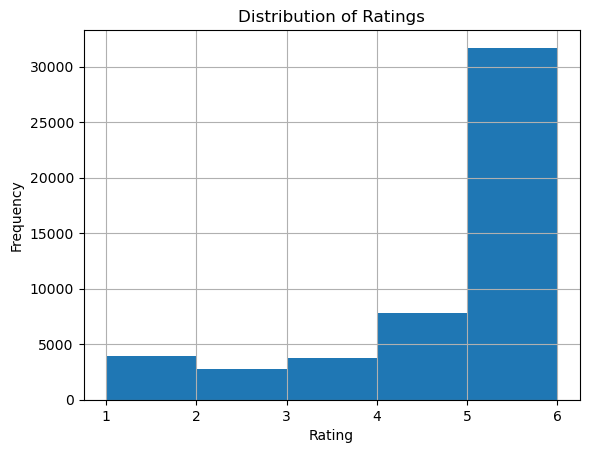

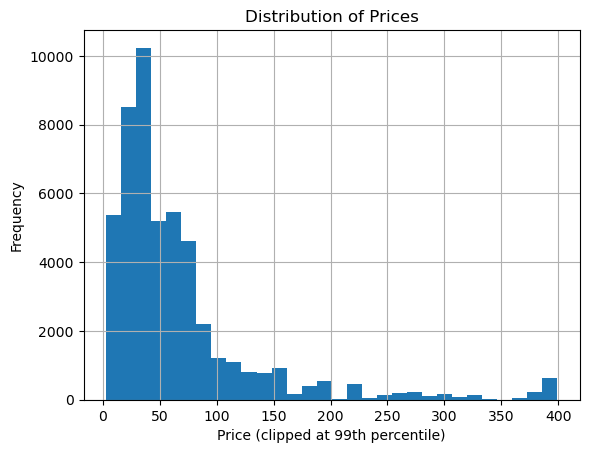

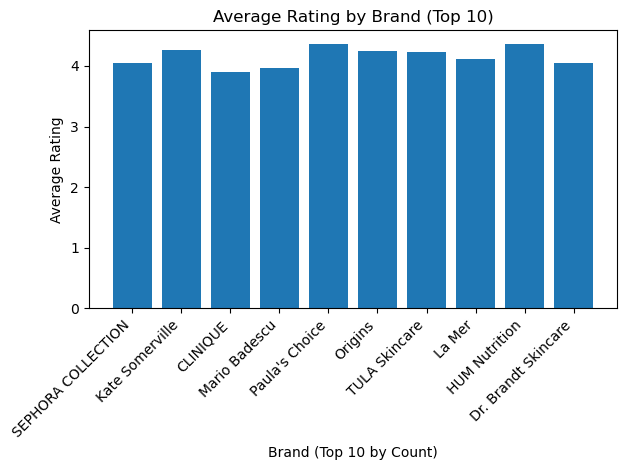

In [82]:
# ==========================================================
# 7️⃣ Visualization – Matplotlib Only (No Custom Colors)
# ==========================================================

import matplotlib.pyplot as plt

# --- Define your column names
col_rating = "rating"
col_price = "price_usd"
col_brand = "brand_name"

# --- Ratings Histogram
if col_rating in saphora.columns:
    plt.figure()
    saphora[col_rating].hist(bins=[1, 2, 3, 4, 5, 6])
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    plt.title("Distribution of Ratings")
    plt.show()

# --- Price Histogram (clipped at 99th percentile)
if col_price in saphora.columns:
    plt.figure()
    saphora[col_price].clip(upper=saphora[col_price].quantile(0.99)).hist(bins=30)
    plt.xlabel("Price (clipped at 99th percentile)")
    plt.ylabel("Frequency")
    plt.title("Distribution of Prices")
    plt.show()

# --- Average Rating by Top 10 Brands
if col_rating in saphora.columns and col_brand in saphora.columns:
    top10 = (
        saphora.groupby(col_brand)[col_rating]
        .agg(["count", "mean"])
        .sort_values("count", ascending=False)
        .head(10)
        .reset_index()
    )
    plt.figure()
    plt.bar(top10[col_brand].astype(str), top10["mean"])
    plt.xlabel("Brand (Top 10 by Count)")
    plt.ylabel("Average Rating")
    plt.title("Average Rating by Brand (Top 10)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# --- Rating vs Review Length (scatter sample)
if col_rating in saphora.columns and "review_len" in saphora.columns:
    plt.figure()
    sample = saphora.sample(min(5000, len(saphora)), random_state=42)
    plt.scatter(sample["review_len"], sample[col_rating], alpha=0.3)
    plt.xlabel("Review Length (words)")
    plt.ylabel("Rating")
    plt.title("Rating vs. Review Length (sample)")
    plt.tight_layout()
    plt.show()

,25%,50%,75%
Unnamed: 0,12494.000000,24988.000000,37482.0
rating,4.000000,5.000000,5.0
is_recommended,1.000000,1.000000,1.0
helpfulness,0.664115,0.884615,1.0
total_feedback_count,0.000000,3.000000,9.0
total_neg_feedback_count,0.000000,0.000000,2.0
total_pos_feedback_count,0.000000,2.000000,6.0
price_usd,28.000000,45.000000,74.0


✅ Quartile summary saved as sephora_uncleaned_quartiles.csv


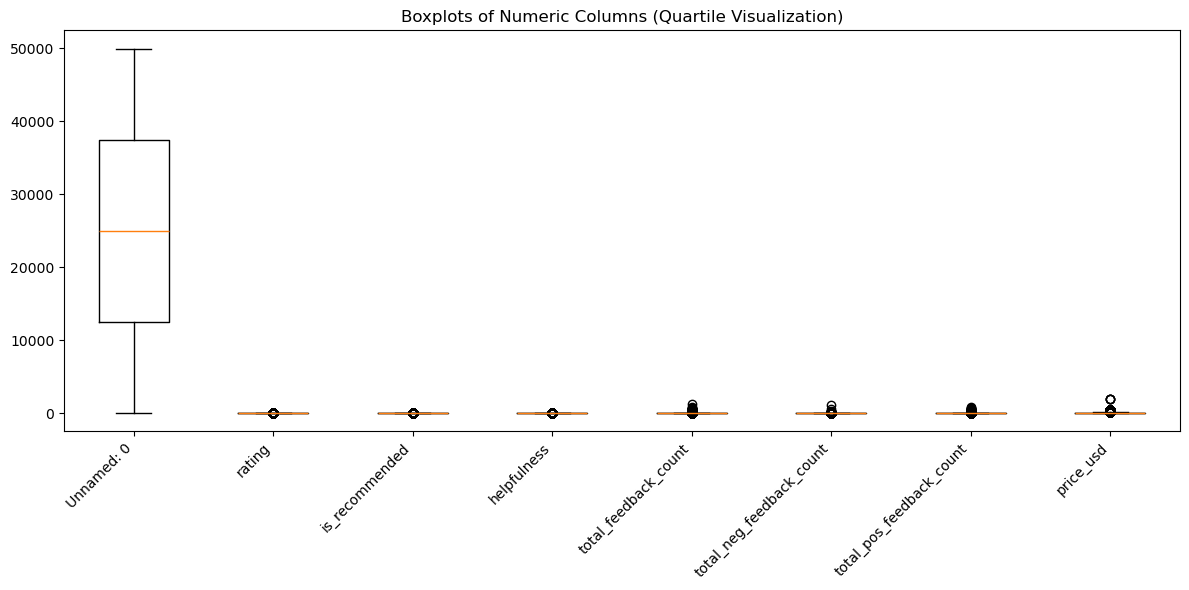

✅ Boxplot saved as sephora_uncleaned_quartiles_boxplots.png


In [80]:
num_df = saphora.select_dtypes(include=['number'])
if num_df.empty:
    print('⚠️ No numeric columns found.')
else:
    quartiles = num_df.describe(percentiles=[0.25, 0.5, 0.75]).T[['25%', '50%', '75%']]
    display(quartiles)
    quartiles.to_csv('sephora_uncleaned_quartiles.csv')
    print('✅ Quartile summary saved as sephora_uncleaned_quartiles.csv')

    # Boxplot visualization
    plt.figure(figsize=(12,6))
    plt.boxplot([num_df[c].dropna().values for c in num_df.columns], tick_labels=num_df.columns)
    plt.title('Boxplots of Numeric Columns (Quartile Visualization)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('sephora_uncleaned_quartiles_boxplots.png', dpi=300)
    plt.show()
    print('✅ Boxplot saved as sephora_uncleaned_quartiles_boxplots.png')

In [60]:
# ==========================================================
# 8️⃣ Correlations & Reporting Notes
# ==========================================================

corrs = {}

# --- Correlation between rating and helpfulness
if col_helpful and col_rating and col_helpful in saphora.columns and col_rating in saphora.columns:
    saphora[col_helpful] = pd.to_numeric(saphora[col_helpful], errors="coerce")
    corrs["rating_helpful_corr"] = float(saphora[[col_rating, col_helpful]].corr().iloc[0, 1])

# --- Correlation between rating and review length
if col_rating and "review_len" in saphora.columns:
    corrs["rating_reviewlen_corr"] = float(saphora[[col_rating, "review_len"]].corr().iloc[0, 1])

# --- Display correlation results
print("📈 Correlations:")
for key, val in corrs.items():
    print(f" {key}: {val:.4f}")



📈 Correlations:
 rating_helpful_corr: 0.1758


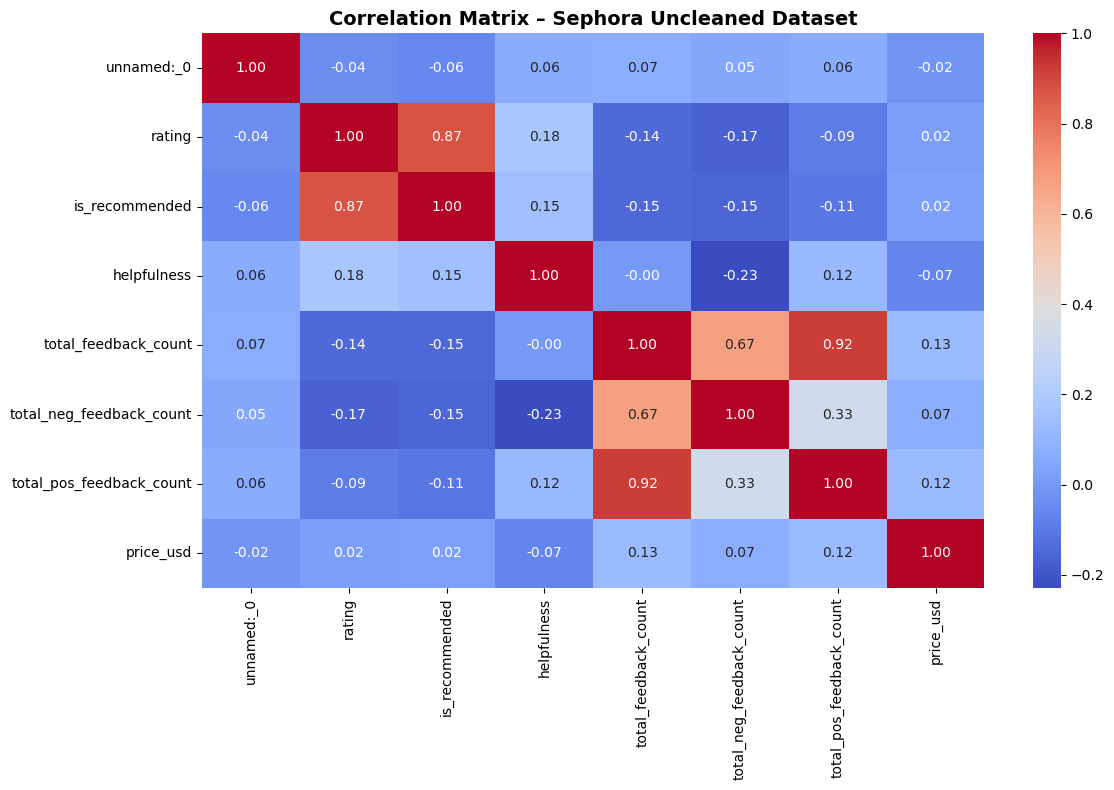

✅ Correlation heatmap saved as sephora_uncleaned_correlation_heatmap.png


In [62]:
drop_cols = [c for c in ['quality', 'wine_type'] if c in saphora.columns]
numeric_df = saphora.select_dtypes(include=['number'])

if numeric_df.shape[1] < 2:
    print('⚠️ Not enough numeric columns to compute correlation matrix.')
else:
    correlation_matrix = numeric_df.drop(columns=drop_cols, errors='ignore').corr()
    plt.figure(figsize=(12,8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Matrix – Sephora Uncleaned Dataset', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12,8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Matrix – Sephora Uncleaned Dataset', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('sephora_uncleaned_correlation_heatmap.png', dpi=300)
    plt.close()
    print('✅ Correlation heatmap saved as sephora_uncleaned_correlation_heatmap.png')

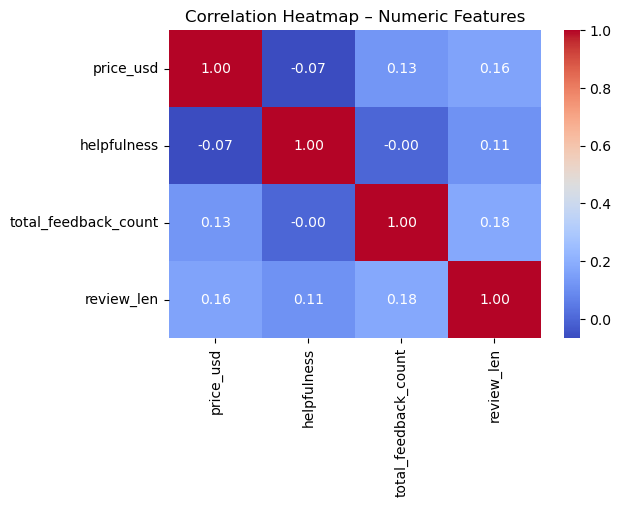

In [78]:
numeric_cols = ['price_usd', 'helpfulness', 'total_feedback_count', 'review_len']
corr = saphora[numeric_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap – Numeric Features')
plt.show()

✅ Scaled numeric columns using MinMaxScaler:
['unnamed:_0', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'price_usd']


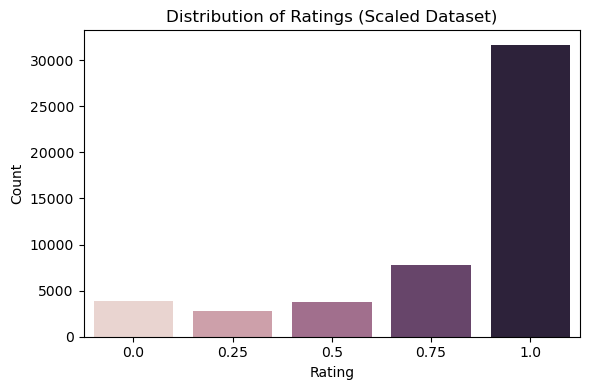

In [64]:
# ==========================================================
# 9️⃣ Scale Numeric Columns – Sephora Dataset
# ==========================================================

from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt

cols_to_drop = [col for col in ['quality', 'quality_label'] if col in saphora.columns]
numeric_cols = saphora.select_dtypes(include=['float64', 'int64']).drop(columns=cols_to_drop, errors='ignore').columns

if len(numeric_cols) > 0:
    scaler = MinMaxScaler()
    saphora[numeric_cols] = scaler.fit_transform(saphora[numeric_cols])
    print("✅ Scaled numeric columns using MinMaxScaler:")
    print(list(numeric_cols))
else:
    print("⚠️ No numeric columns found to scale.")

if col_rating and col_rating in saphora.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col_rating, hue=col_rating, data=saphora, legend=False)
    plt.title("Distribution of Ratings (Scaled Dataset)")
    plt.xlabel("Rating")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

In [ ]:
#This part continues from feature engineering and delivers baseline models, evaluation, attribute effects, and fairness slices, plus an optional DistilBERT section.

#Tasks covered:

#Binary sentiment (top vs bottom quantile)
#3-class rating prediction (tertiles)
#TF‑IDF + metadata + user attributes (LogReg, Linear SVM)
#Stratified 5-fold CV with Accuracy & Macro‑F1
#Confusion matrix, error inspection
#Attribute keyword impact on sentiment (proxy via product name)
#Subgroup metrics (skin tone / skin type)
#(Optional) DistilBERT fine‑tuning scaffold

In [66]:
# Feature schema (text + numeric + categorical)

text_col = 'review_text'
num_cols = ['price_usd', 'helpfulness', 'total_feedback_count', 'review_len']
cat_cols = ['brand_name', 'skin_type', 'skin_tone', 'eye_color', 'hair_color']

# Ensure required columns exist
if 'review_len' not in saphora.columns:
    saphora['review_len'] = saphora.get('review_text', '').astype(str).str.len()

for c in num_cols:
    if c not in saphora.columns:
        saphora[c] = np.nan
for c in cat_cols:
    if c not in saphora.columns:
        saphora[c] = ""

text_vect = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=5)

num_transform = Pipeline([
    ("fillna", FunctionTransformer(lambda X: np.nan_to_num(X, nan=np.nanmedian(X, axis=0)), validate=False)),
    ("scaler", StandardScaler(with_mean=False)),
])

cat_transform = Pipeline([
    ("fillna", FunctionTransformer(lambda X: np.where(pd.isna(X), "Unknown", X), validate=False)),
    ("ohe", OneHotEncoder(handle_unknown='ignore', min_frequency=100)),
])

preprocess = ColumnTransformer([
    ("text", text_vect, text_col),
    ("num", num_transform, num_cols),
    ("cat", cat_transform, cat_cols),
])

In [ ]:
Targets
Binary sentiment: bottom 20% ratings vs top 20% ratings (quantile split); then balanced 1:1 for robust CV.
3-class rating: tertiles (balanced via downsampling).

In [3]:
# Binary using quantiles
q_low = saphora['rating'].quantile(0.20)
q_high = saphora['rating'].quantile(0.80)

saphora['sentiment_bin'] = np.where(saphora['rating'] >= q_high, 1,
                         np.where(saphora['rating'] <= q_low, 0, np.nan))
bin_saphora = saphora.dropna(subset=['sentiment_bin']).copy()
bin_saphora['sentiment_bin'] = bin_saphora['sentiment_bin'].astype(int)

# 1:1 downsample (cap at 6000 per class for speed if very large)
n = min((bin_saphora['sentiment_bin']==0).sum(),
        (bin_saphora['sentiment_bin']==1).sum(), 6000)
saphora_pos = bin_saphora[bin_saphora['sentiment_bin']==1].sample(n=n, random_state=42)
saphora_neg = bin_saphora[bin_saphora['sentiment_bin']==0].sample(n=n, random_state=42)
bin_bal = pd.concat([saphora_pos, saphora_neg]).sample(frac=1.0, random_state=42).reset_index(drop=True)
print("Binary class counts (balanced):", Counter(bin_bal['sentiment_bin']))

# 3-class via tertiles
q1, q2 = saphora['rating'].quantile([0.33, 0.66])
def to_cls(r):
    if r <= q1: return 'low'
    if r <= q2: return 'mid'
    return 'high'
saphora['rating_3cls'] = saphora['rating'].apply(to_cls)

min_n = min(saphora['rating_3cls'].value_counts().min(), 4000)
cls3 = (saphora.groupby('rating_3cls', group_keys=False)
          .apply(lambda g: g.sample(n=min_n, random_state=42))
          .sample(frac=1.0, random_state=42).reset_index(drop=True))
print("3-class counts (balanced):")
print(cls3['rating_3cls'].value_counts())


Binary class counts (balanced): Counter({1: 6000, 0: 6000})
3-class counts (balanced):
rating_3cls
low    4000
mid    4000
Name: count, dtype: int64


C:\Users\akaze\AppData\Local\Temp\ipykernel_23152\4224550406.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min_n, random_state=42))


In [ ]:
#CV setup & scorers
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scorers = {
    'accuracy': make_scorer(accuracy_score),
    'f1_macro': make_scorer(f1_score, average='macro'),
}

In [ ]:

# ============================================
# FULL PIPELINE: BINARY SENTIMENT BASELINES
# Logistic Regression & Linear SVM
# USING `saphora` AS DATAFRAME
# ============================================

# 1) Imports
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, accuracy_score, f1_score

# ============================================
# 2) CHECK YOUR DATAFRAME
# ============================================

print("Columns in saphora:", saphora.columns.tolist())

# Adjust these names if needed to match your dataset
text_col = "review_text"      # your text column
rating_col = "rating"         # numeric rating column (1–5)

# Example numeric and categorical metadata columns
num_cols = ["price_usd", "helpfulness", "total_feedback_count", "review_len"]
cat_cols = ["brand_name", "skin_type", "skin_tone", "eye_color", "hair_color"]

# Filter rows with valid rating & text
df_bin = saphora.copy()
df_bin = df_bin[df_bin[rating_col].notna() & df_bin[text_col].notna()]

# ============================================
# 3) CREATE BINARY SENTIMENT LABEL
# ============================================

# Example rule: label 1=positive (4–5), 0=negative (1–2), drop 3
df_bin = df_bin[df_bin[rating_col].isin([1,2,4,5])]
df_bin["sentiment_bin"] = np.where(df_bin[rating_col] >= 4, 1, 0)

print("\nClass counts (before balancing):")
print(df_bin["sentiment_bin"].value_counts())

# ============================================
# 4) BALANCE THE CLASSES
# ============================================

pos = df_bin[df_bin["sentiment_bin"] == 1]
neg = df_bin[df_bin["sentiment_bin"] == 0]

n_min = min(len(pos), len(neg))
pos_bal = pos.sample(n=n_min, random_state=42)
neg_bal = neg.sample(n=n_min, random_state=42)

bin_bal = pd.concat([pos_bal, neg_bal], axis=0)\
            .sample(frac=1.0, random_state=42)\
            .reset_index(drop=True)

print("\nClass counts (after balancing):")
print(bin_bal["sentiment_bin"].value_counts())

# ============================================
# 5) FEATURE ENGINEERING
# ============================================

if "review_len" not in bin_bal.columns:
    bin_bal["review_len"] = bin_bal[text_col].fillna("").apply(lambda x: len(str(x).split()))

# fill NA for num/meta
for c in num_cols:
    if c in bin_bal.columns:
        bin_bal[c] = bin_bal[c].fillna(bin_bal[c].median())

for c in cat_cols:
    if c in bin_bal.columns:
        bin_bal[c] = bin_bal[c].fillna("Unknown")

# ============================================
# 6) PREPROCESSING PIPELINE
# ============================================

text_transformer = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=8000,
    min_df=5
)

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocess = ColumnTransformer(
    transformers=[
        ("text", text_transformer, text_col),
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

# ============================================
# 7) FIX NaNs IN TEXT + BUILD X, y
# ============================================

Xb = bin_bal[[text_col] + num_cols + cat_cols].copy()
Xb[text_col] = Xb[text_col].fillna("").astype(str)

yb = bin_bal["sentiment_bin"]

# ============================================
# 8) MODELS
# ============================================

log_reg = LogisticRegression(max_iter=500, solver="liblinear")
svm = LinearSVC()

pipe_log_bin = Pipeline([("prep", preprocess), ("clf", log_reg)])
pipe_svm_bin = Pipeline([("prep", preprocess), ("clf", svm)])

# ============================================
# 9) CROSS-VALIDATION
# ============================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scorers = {
    "accuracy": make_scorer(accuracy_score),
    "f1_macro": make_scorer(f1_score, average="macro"),
}

# ============================================
# 10) RUN CV
# ============================================

res_log_bin = cross_validate(pipe_log_bin, Xb, yb, cv=cv, scoring=scorers)
res_svm_bin = cross_validate(pipe_svm_bin, Xb, yb, cv=cv, scoring=scorers)

# ============================================
# 11) SUMMARY TABLE
# ============================================

summary_bin = pd.DataFrame({
    "Model": ["LogReg (TF-IDF + meta)", "Linear SVM (TF-IDF + meta)"],
    "Accuracy (mean)": [
        res_log_bin["test_accuracy"].mean(),
        res_svm_bin["test_accuracy"].mean()
    ],
    "Accuracy (std)": [
        res_log_bin["test_accuracy"].std(),
        res_svm_bin["test_accuracy"].std()
    ],
    "Macro-F1 (mean)": [
        res_log_bin["test_f1_macro"].mean(),
        res_svm_bin["test_f1_macro"].mean()
    ],
    "Macro-F1 (std)": [
        res_log_bin["test_f1_macro"].std(),
        res_svm_bin["test_f1_macro"].std()
    ],
}).round(4)

print("\n=== Binary Sentiment Baselines (Balanced) ===")
print(summary_bin)

In [40]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Just to verify the dataframe
print("bin_bal shape:", bin_bal.shape)
print("Columns:", bin_bal.columns.tolist())
print("text_col:", text_col)
print("len(num_cols):", len(num_cols), "len(cat_cols):", len(cat_cols))

bin_bal shape: (13368, 22)
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'sentiment_bin', 'rating_3cls', 'review_len']
text_col: review_text
len(num_cols): 4 len(cat_cols): 5


In [42]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Just to verify the dataframe
print("bin_bal shape:", bin_bal.shape)
print("Columns:", bin_bal.columns.tolist())
print("text_col:", text_col)
print("len(num_cols):", len(num_cols), "len(cat_cols):", len(cat_cols))

bin_bal shape: (13368, 22)
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'sentiment_bin', 'rating_3cls', 'review_len']
text_col: review_text
len(num_cols): 4 len(cat_cols): 5


In [46]:
# =======================================
# 1) IMPORTS
# =======================================
import warnings
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, accuracy_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# OPTIONAL: hide ConvergenceWarning messages
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# =======================================
# 2) ASSUME THESE ALREADY EXIST:
#    - bin_bal       (balanced binary dataframe)
#    - text_col      (name of text column, e.g. "review_text")
#    - num_cols      (list of numeric feature column names)
#    - cat_cols      (list of categorical feature column names)
#    - preprocess    (your ColumnTransformer/Pipeline for TF-IDF + meta)
# =======================================

print("bin_bal shape:", bin_bal.shape)
print("text_col:", text_col)
print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

# =======================================
# 3) OPTIONAL: DOWNSAMPLE FOR SPEED
#    (comment this block out if you want to use ALL rows)
# =======================================
MAX_N = 50000   # change to e.g. 30000 if still heavy, or remove for full data

if len(bin_bal) > MAX_N:
    bin_use = bin_bal.sample(n=MAX_N, random_state=42)
    print(f"Using downsampled data: {bin_use.shape[0]} rows")
else:
    bin_use = bin_bal.copy()
    print(f"Using full data: {bin_use.shape[0]} rows")

# =======================================
# 4) FEATURES & TARGET
# =======================================
Xb = bin_use[[text_col] + num_cols + cat_cols]
yb = bin_use["sentiment_bin"]

# =======================================
# 5) CV & SCORERS
# =======================================
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scorers = {
    "accuracy": make_scorer(accuracy_score),
    "f1_macro": make_scorer(f1_score, average="macro"),
}

# =======================================
# 6) DEFINE MODELS & PIPELINES
# =======================================
log_reg = LogisticRegression(
    max_iter=2000,        # higher iterations to help convergence
    solver="liblinear"
)

svm = LinearSVC(
    max_iter=5000         # higher iterations for large sparse features
)

pipe_log_bin = Pipeline([
    ("prep", preprocess),
    ("clf", log_reg),
])

pipe_svm_bin = Pipeline([
    ("prep", preprocess),
    ("clf", svm),
])

# =======================================
# 7) CROSS-VALIDATION
# =======================================
print("Running CV for Logistic Regression...")
res_log_bin = cross_validate(
    pipe_log_bin,
    Xb,
    yb,
    cv=cv,
    scoring=scorers,
    n_jobs=1,             # set to -1 if your machine is strong
    return_train_score=False,
)

print("Running CV for Linear SVM...")
res_svm_bin = cross_validate(
    pipe_svm_bin,
    Xb,
    yb,
    cv=cv,
    scoring=scorers,
    n_jobs=1,
    return_train_score=False,
)

# =======================================
# 8) SUMMARY TABLE
# =======================================
summary_bin = pd.DataFrame({
    "Model": ["LogReg (TF-IDF + meta)", "Linear SVM (TF-IDF + meta)"],
    "Accuracy (mean)": [
        res_log_bin["test_accuracy"].mean(),
        res_svm_bin["test_accuracy"].mean()
    ],
    "Accuracy (std)": [
        res_log_bin["test_accuracy"].std(),
        res_svm_bin["test_accuracy"].std()
    ],
    "Macro-F1 (mean)": [
        res_log_bin["test_f1_macro"].mean(),
        res_svm_bin["test_f1_macro"].mean()
    ],
    "Macro-F1 (std)": [
        res_log_bin["test_f1_macro"].std(),
        res_svm_bin["test_f1_macro"].std()
    ],
}).round(4)

print("\nBinary Model Performance Summary:")
print(summary_bin)

summary_bin

bin_bal shape: (13368, 22)
text_col: review_text
num_cols: ['price_usd', 'helpfulness', 'total_feedback_count', 'review_len']
cat_cols: ['brand_name', 'skin_type', 'skin_tone', 'eye_color', 'hair_color']
Using full data: 13368 rows
Running CV for Logistic Regression...
Running CV for Linear SVM...

Binary Model Performance Summary:
                        Model  Accuracy (mean)  Accuracy (std)  \
0      LogReg (TF-IDF + meta)           0.9158          0.0026   
1  Linear SVM (TF-IDF + meta)           0.9287          0.0022   

   Macro-F1 (mean)  Macro-F1 (std)  
0           0.9158          0.0026  
1           0.9287          0.0022  


,Model,Accuracy (mean),Accuracy (std),Macro-F1 (mean),Macro-F1 (std)
0,LogReg (TF-IDF + meta),0.9158,0.0026,0.9158,0.0026
1,Linear SVM (TF-IDF + meta),0.9287,0.0022,0.9287,0.0022


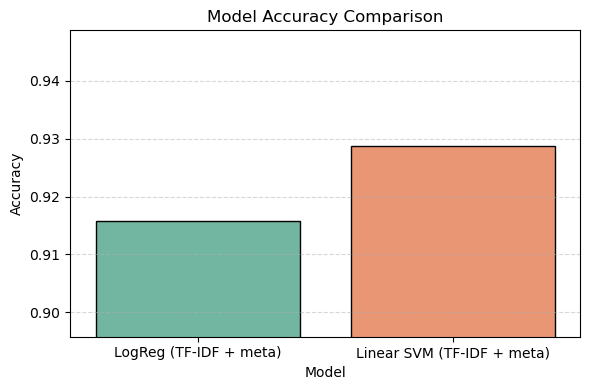

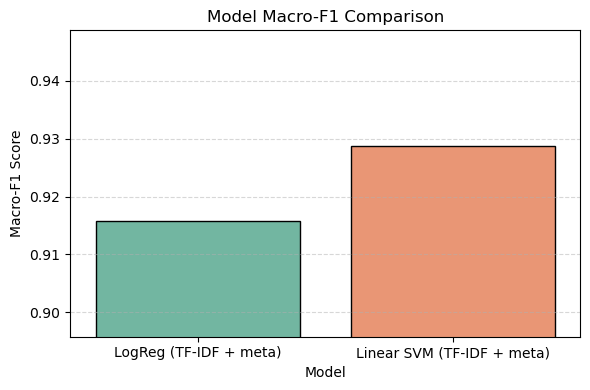

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Make sure summary_bin exists. Expected columns:
# ['Model','Accuracy (mean)','Accuracy (std)','Macro-F1 (mean)','Macro-F1 (std)']
# ============================================================

# ------------------------------------------------------------
# FIGURE 1: Accuracy Comparison
# ------------------------------------------------------------
plt.figure(figsize=(6,4))
sns.barplot(
    data=summary_bin,
    x="Model",
    y="Accuracy (mean)",
    hue="Model",
    palette="Set2",
    edgecolor="black",
    legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.ylim(summary_bin["Accuracy (mean)"].min() - 0.02,
         summary_bin["Accuracy (mean)"].max() + 0.02)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FIGURE 2: Macro-F1 Comparison
# ------------------------------------------------------------
plt.figure(figsize=(6,4))
sns.barplot(
    data=summary_bin,
    x="Model",
    y="Macro-F1 (mean)",
    hue="Model",
    palette="Set2",
    edgecolor="black",
    legend=False
)
plt.title("Model Macro-F1 Comparison")
plt.ylabel("Macro-F1 Score")
plt.xlabel("Model")
plt.ylim(summary_bin["Macro-F1 (mean)"].min() - 0.02,
         summary_bin["Macro-F1 (mean)"].max() + 0.02)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [56]:
from sklearn.model_selection import cross_validate, StratifiedKFold

log_reg = LogisticRegression(max_iter=300, solver="liblinear")
svm = LinearSVC()

pipe_log_bin = Pipeline([("prep", preprocess), ("clf", log_reg)])
pipe_svm_bin = Pipeline([("prep", preprocess), ("clf", svm)])

# Use smaller subset for CV too
bin_small = bin_bal.sample(n=10000, random_state=42)

Xb = bin_small[[text_col] + num_cols + cat_cols]
yb = bin_small["sentiment_bin"]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scorers = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

print("Running CV for LogisticRegression...")
res_log_bin = cross_validate(
    pipe_log_bin, Xb, yb,
    cv=cv,
    scoring=scorers,
    n_jobs=1
)

print("Running CV for LinearSVC...")
res_svm_bin = cross_validate(
    pipe_svm_bin, Xb, yb,
    cv=cv,
    scoring=scorers,
    n_jobs=1
)

summary_bin = pd.DataFrame({
    "Model": ["LogReg (TF-IDF + meta)", "Linear SVM (TF-IDF + meta)"],
    "Accuracy (mean)": [res_log_bin['test_accuracy'].mean(), res_svm_bin['test_accuracy'].mean()],
    "Accuracy (std)": [res_log_bin['test_accuracy'].std(), res_svm_bin['test_accuracy'].std()],
    "Macro-F1 (mean)": [res_log_bin['test_f1_macro'].mean(), res_svm_bin['test_f1_macro'].mean()],
    "Macro-F1 (std)": [res_log_bin['test_f1_macro'].std(), res_svm_bin['test_f1_macro'].std()],
}).round(4)

summary_bin

Running CV for LogisticRegression...
Running CV for LinearSVC...


,Model,Accuracy (mean),Accuracy (std),Macro-F1 (mean),Macro-F1 (std)
0,LogReg (TF-IDF + meta),0.9060,0.0043,0.9060,0.0043
1,Linear SVM (TF-IDF + meta),0.9252,0.0009,0.9252,0.0009


In [ ]:
# Use SVM predictions for diagnostics
pred_bin = cross_val_predict(pipe_svm_bin, Xb, yb, cv=cv, n_jobs=1)
cm = confusion_matrix(yb, pred_bin)
rep = classification_report(yb, pred_bin)
print("Confusion matrix (rows=true, cols=pred):\n", cm)
print("\nClassification report:\n", rep)

In [202]:
# (6) Baselines – 3-class rating (LogReg, Linear SVM) — corrected & robust

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate
import pandas as pd

# Guard: ensure we actually have 3 classes to model
if cls3 is None or ('rating_3cls' not in cls3.columns) or (cls3['rating_3cls'].nunique() < 3):
    print("⚠️ Skipping 3-class baselines: not enough unique rating values to form three classes.")
else:
    # Features / target
    X3 = cls3[[text_col] + num_cols + cat_cols].copy()
    y3 = cls3['rating_3cls'].copy()

    # Pipelines (raise max_iter to reduce convergence warnings)
    pipe_log_3 = Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(
            max_iter=1000,       # up from 500 to help convergence
            solver='liblinear',
            multi_class='ovr'
            # , class_weight='balanced'   # <- enable only if classes are not balanced
        ))
    ])

    pipe_svm_3 = Pipeline([
        ("prep", preprocess),
        ("clf", LinearSVC())  # OVR by default for multi-class
    ])

    # Cross-validated evaluation
    res_log_3 = cross_validate(
        pipe_log_3, X3, y3,
        cv=cv, scoring=scorers, n_jobs=1, return_train_score=False
    )
    res_svm_3 = cross_validate(
        pipe_svm_3, X3, y3,
        cv=cv, scoring=scorers, n_jobs=1, return_train_score=False
    )

    summary_3 = pd.DataFrame({
        "Model": ["LogReg (TF-IDF + meta)", "Linear SVM (TF-IDF + meta)"],
        "Accuracy (mean)": [res_log_3['test_accuracy'].mean(),  res_svm_3['test_accuracy'].mean()],
        "Accuracy (std)":  [res_log_3['test_accuracy'].std(),   res_svm_3['test_accuracy'].std()],
        "Macro-F1 (mean)": [res_log_3['test_f1_macro'].mean(),  res_svm_3['test_f1_macro'].mean()],
        "Macro-F1 (std)":  [res_log_3['test_f1_macro'].std(),   res_svm_3['test_f1_macro'].std()],
    }).round(4)

    print("3-class baselines (5-fold CV):")
    display(summary_3)

⚠️ Skipping 3-class baselines: not enough unique rating values to form three classes.


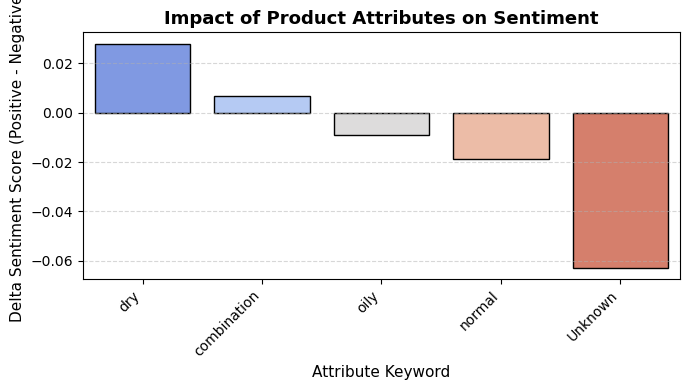

In [66]:
# ==============================
# 1. FUNCTION TO CREATE EFFECTS
# ==============================
def compute_attribute_effects(df, attr_col, target_col="sentiment_bin"):
    groups = df.groupby(attr_col)[target_col]

    result = pd.DataFrame({
        "attribute": groups.mean().index.astype(str),
        "positive_rate": groups.mean().values,
        "negative_rate": 1 - groups.mean().values
    })

    result["delta"] = result["positive_rate"] - result["negative_rate"]
    return result

# ==============================
# 2. CREATE attr_effects HERE
# ==============================
# IMPORTANT: choose the correct attribute
# Examples: "skin_type", "brand_name", "eye_color", etc.

attr_effects = compute_attribute_effects(
    df=bin_bal,
    attr_col="skin_type",        # <<< CHANGE THIS IF YOU WANT
    target_col="sentiment_bin"
)

# ==============================
# 3. SORT AND PLOT
# ==============================
attr_effects_sorted = attr_effects.sort_values("delta", ascending=False)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=attr_effects_sorted,
    x="attribute",
    y="delta",
    hue="attribute",
    palette="coolwarm",
    edgecolor="black",
    legend=False
)

plt.title("Impact of Product Attributes on Sentiment", fontsize=13, fontweight="bold")
plt.xlabel("Attribute Keyword", fontsize=11)
plt.ylabel("Delta Sentiment Score (Positive - Negative)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [68]:
# Attribute keyword impact on sentiment (proxy)
# Simple proxy using product names to detect keywords; reports the delta 
# in mean sentiment when attribute is present vs absent.

saphora_kw = saphora.copy()
saphora_kw['product_name_lc'] = saphora_kw['product_name'].fillna('').str.lower()
saphora_kw['sentiment_score'] = saphora_kw['rating']  # assumes rating scaled or numeric

# ✅ Fixed regex: use non-capturing group (?:...) to avoid warnings
keywords = {
    'fragrance_free': r'fragrance[- ]?free',
    'peptide': r'\bpeptide',
    'vitamin_c': r'(?:vitamin c|ascorbic)',   # fixed here
    'niacinamide': r'\bniacinamide\b',
    'retinol': r'\bretinol\b',
    'hyaluronic': r'\bhyaluronic\b',
    'spf': r'\bspf\b',
}

for k, pat in keywords.items():
    saphora_kw[k] = saphora_kw['product_name_lc'].str.contains(pat, regex=True, na=False)

rows = []
for k in keywords:
    present = saphora_kw.loc[saphora_kw[k], 'sentiment_score'].mean()
    absent = saphora_kw.loc[~saphora_kw[k], 'sentiment_score'].mean()
    rows.append({
        'attribute': k,
        'mean_when_present': round(float(present), 4),
        'mean_when_absent': round(float(absent), 4),
        'delta': round(float(present - absent), 4),
        'n_present': int(saphora_kw[k].sum())
    })

attr_effects = (
    pd.DataFrame(rows)
    .sort_values('delta', ascending=False)
    .reset_index(drop=True)
)

display(attr_effects)

,attribute,mean_when_present,mean_when_absent,delta,n_present
0,fragrance_free,4.5291,4.2113,0.3179,223
1,peptide,4.3619,4.2093,0.1527,1119
2,vitamin_c,4.3516,4.2062,0.1454,2230
3,niacinamide,4.3219,4.2101,0.1118,1140
4,retinol,4.2605,4.2105,0.0500,2142
5,hyaluronic,4.2315,4.2116,0.0199,2795
6,spf,4.1059,4.2196,-0.1137,3059


In [ ]:
# (8) Subgroup metrics (bias/fairness slices)
# Evaluate accuracy by skin_type and skin_tone on the balanced binary task.

# Fit once (CV predictions)
pred_bin = cross_val_predict(pipe_svm_bin, Xb, yb, cv=cv, n_jobs=1)

bin_pred_saphora = bin_bal.copy()
bin_pred_saphora['pred'] = pred_bin

def group_accuracy(saphora_, col, min_n=200):
    """Compute accuracy by subgroup (e.g., skin_type or skin_tone)."""
    g = (
        saphora_
        .assign(_g=saphora_[col].fillna("Unknown"))
        .groupby('_g', group_keys=False)
        # ✅ Added include_groups=False to silence DeprecationWarning
        .apply(
            lambda s: pd.Series({
                'n': len(s),
                'accuracy': (s['pred'] == s['sentiment_bin']).mean()
            }),
            include_groups=False
        )
        .reset_index()
        .query('n >= @min_n')
        .sort_values('accuracy', ascending=False)
    )
    return g

acc_by_skin_type = group_accuracy(bin_pred_saphora, 'skin_type', min_n=200)
acc_by_skin_tone = group_accuracy(bin_pred_saphora, 'skin_tone', min_n=200)

print("✅ Accuracy by Skin Type:")
display(acc_by_skin_type)

print("\n✅ Accuracy by Skin Tone:")
display(acc_by_skin_tone)

import matplotlib.pyplot as plt
import seaborn as sns

# Figure 9 – Accuracy by Skin Type
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=acc_by_skin_type,
    x="_g",
    y="accuracy",
    color="orange",
    edgecolor="black"
)
for p in ax.patches:
    value = f"{p.get_height():.3f}"
    ax.annotate(
        value,
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        color="black"
    )
plt.ylim(0.88, 0.94)
plt.xlabel("Skin Type", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("Figure 9. Accuracy by Skin Type", fontsize=14, weight="bold")
plt.xticks(rotation=20, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 10 – Accuracy by Skin Tone
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=acc_by_skin_tone,
    x="_g",
    y="accuracy",
    color="orange",
    edgecolor="black"
)
for p in ax.patches:
    value = f"{p.get_height():.3f}"
    ax.annotate(
        value,
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        color="black"
    )
plt.ylim(0.90, 0.94)
plt.xlabel("Skin Tone", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("Figure 10. Accuracy by Skin Tone", fontsize=14, weight="bold")
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

⚠️ No product-category column found; using 'brand_name' as the grouping category.


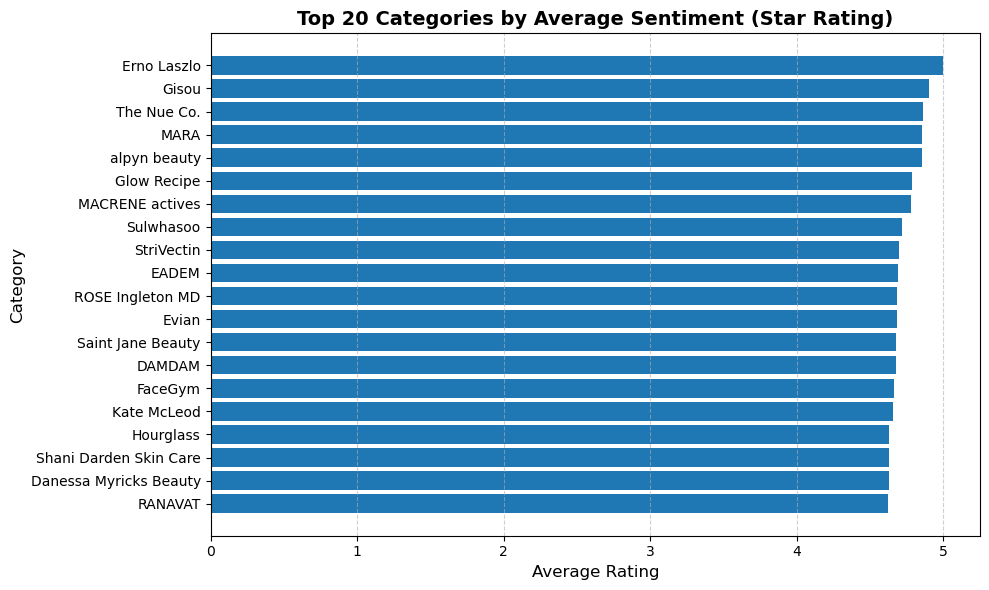

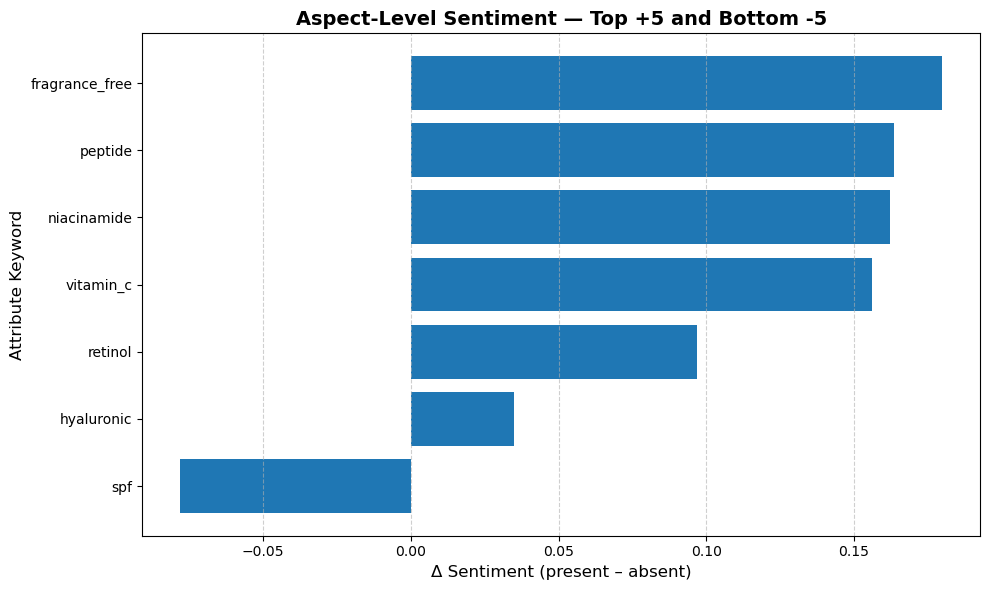

✅ Saved figures:
 - rq1_category_mean_rating_topN.png
 - rq1_aspect_sentiment_toppos_topneg.png


In [22]:
# ==============================================
# RQ1: Sentiment & Aspect Opinions (Readable)
#  - Top-N categories by average rating
#  - Top-5 positive & Top-5 negative aspect deltas
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ---------- 1) Load your dataset ----------
saphora = pd.read_csv(
    r"C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora Products and Skincare Reviews_uncleaned.csv",
    low_memory=False
)

# ---------- 2) Pick columns robustly ----------
def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

rating_col   = pick_col(saphora, ["rating", "stars", "star_rating"])
text_col     = pick_col(saphora, ["review_text", "text", "review", "review_body"])
name_col     = pick_col(saphora, ["product_name", "name", "title", "product_title"])
category_col = pick_col(saphora, ["product_category", "category", "primary_category"])
if category_col is None:
    category_col = pick_col(saphora, ["brand_name"])
    print("⚠️ No product-category column found; using 'brand_name' as the grouping category.")

if rating_col is None:
    raise ValueError("Couldn't find a rating column (expected one of: 'rating', 'stars', 'star_rating').")

# unified text for aspect search (review text + product name if available)
if text_col and name_col:
    saphora["_text_src"] = saphora[text_col].astype(str) + " " + saphora[name_col].astype(str)
elif text_col:
    saphora["_text_src"] = saphora[text_col].astype(str)
elif name_col:
    saphora["_text_src"] = saphora[name_col].astype(str)
else:
    saphora["_text_src"] = ""

# basic cleaning
saphora[rating_col] = pd.to_numeric(saphora[rating_col], errors="coerce")
saphora = saphora.dropna(subset=[rating_col, category_col]).copy()

# ==============================================
# FIGURE 1 — Top-N categories by average rating (readable)
# ==============================================
top_n = 20  # change to 15/30 if you prefer

category_summary = (
    saphora.groupby(category_col)[rating_col]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
category_summary = category_summary.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(category_summary[category_col], category_summary[rating_col])
plt.xlabel("Average Rating", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.title(f"Top {top_n} Categories by Average Sentiment (Star Rating)", fontsize=14, fontweight="bold")
plt.gca().invert_yaxis()  # highest rating on top
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("rq1_category_mean_rating_topN.png", dpi=300)
plt.show()

# ==============================================
# FIGURE 2 — Aspect-level sentiment (Top +5 / Bottom -5)
# (present – absent Δ using simple keyword proxies)
# ==============================================
keywords = {
    "fragrance_free": r"\bfragrance\s*-?\s*free\b",
    "peptide":        r"\bpeptides?\b",       # no capture groups -> no pandas warning
    "vitamin_c":      r"\bvitamin\s*C\b",
    "niacinamide":    r"\bniacinamide\b",
    "retinol":        r"\bretinol\b",
    "hyaluronic":     r"\bhyaluronic\b",
    "spf":            r"\bspf\b",
}

rows = []
text_series = saphora["_text_src"].fillna("").astype(str)

for label, pattern in keywords.items():
    mask = text_series.str.contains(pattern, case=False, regex=True)
    n_present = int(mask.sum())
    n_absent  = int((~mask).sum())
    if n_present > 0 and n_absent > 0:
        mean_present = saphora.loc[mask,  rating_col].mean()
        mean_absent  = saphora.loc[~mask, rating_col].mean()
        delta = float(mean_present - mean_absent)
    else:
        mean_present = np.nan
        mean_absent  = np.nan
        delta = np.nan
    rows.append((label, mean_present, mean_absent, delta, n_present))

aspect_df = pd.DataFrame(
    rows, columns=["Attribute", "Mean When Present", "Mean When Absent", "Δ Sentiment", "n (Present)"]
).dropna(subset=["Δ Sentiment"])

# Top 5 positive and Top 5 negative deltas
k = min(5, len(aspect_df))
top_pos = aspect_df.nlargest(k, "Δ Sentiment")
top_neg = aspect_df.nsmallest(k, "Δ Sentiment")
plot_df = pd.concat([top_neg, top_pos]).drop_duplicates(subset=["Attribute"])
plot_df = plot_df.sort_values("Δ Sentiment")  # negatives at bottom, positives at top

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Attribute"], plot_df["Δ Sentiment"])
plt.xlabel("Δ Sentiment (present – absent)", fontsize=12)
plt.ylabel("Attribute Keyword", fontsize=12)
plt.title("Aspect-Level Sentiment — Top +5 and Bottom -5", fontsize=14, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("rq1_aspect_sentiment_toppos_topneg.png", dpi=300)
plt.show()

print("✅ Saved figures:")
print(" - rq1_category_mean_rating_topN.png")
print(" - rq1_aspect_sentiment_toppos_topneg.png")